# 🪙 Crypto Hyper-Volatility: Bitcoin Multi-Cycle Booms & Collapses (2015–Present)
## Parabolic Speculative Surges, Multi-Day Flash Crashes & -80% Drawdowns

### 1. Incident Background & Multi-Cycle Anatomy
Cryptocurrency markets represent the highest-volatility liquid asset class in existence. Because crypto operates **24/7/365 without exchange circuit breakers, price limit collars, or government backstops**, it exhibits extreme recurring cycles: parabolic upside price explosions followed by catastrophic flash crashes and multi-year "crypto winters".

Major recurring spikes and crashes featured in this dataset:
* **2017 Mania Run-up & 2018 Burst:** Surged from **$1,000 $\rightarrow$ $19,800** (+1,880%), followed by an **-84.0%** collapse down to **$3,150** in late 2018.
* **March 12, 2020 "Black Thursday" Liquidity Liquidation:** Cascading automated margin calls drove a **-50.0% flash drop** in under 24 hours ($7,900 $\rightarrow$ $3,850).
* **Spring 2021 All-Time High Run:** Surged to **$64,800** in April 2021.
* **May 2021 China Mining Ban & ESG Shock:** Plunged from **$64,800 $\rightarrow$ $30,000** (**-53.7%**) in 10 days.
* **November 2021 Cycle Peak:** Reached **$68,789** peak before entering the 2022 Contagion Cascade.
* **2022 Crypto Contagion Triple-Crash:**
  1. *May 2022:* Terra/Luna algorithmic stablecoin death spiral ($40,000 $\rightarrow$ $28,000).
  2. *June 2022:* Celsius Network and Three Arrows Capital (3AC) bankruptcy ($28,000 $\rightarrow$ $19,000).
  3. *November 2022:* FTX & Alameda Research fraud collapse ($21,000 $\rightarrow$ **$15,500**, an overall **-77.5%** drawdown).
* **2024 Institutional Spot ETF Inflow Surge:** Vertical expansion to **$73,700+** followed by sharp $10k+ flash pullbacks.

### 2. Target Variables ($y$)
* **`BTC_close`**: Daily Bitcoin / US Dollar closing price.
* **`daily_return_pct`**: 24-hour percentage price return.
* **`drawdown_pct`**: Realized peak-to-date drawdown percentage.
* **`mayer_multiple`**: Ratio of price to its 200-day Simple Moving Average ($P_t / \text{SMA}_{200}$).

### 3. Data Source
* Direct Yahoo Finance REST API (`BTC-USD`, 2015–Present).
* Fully reproducible with offline fallback caching to `./data/`.


### 📚 Academic Citations & Benchmark Lineage
* **Cryptocurrency Asset Pricing:** Liu, Y., & Tsyvinski, A. (2021). *"Risks and Returns of Cryptocurrency."* *The Review of Financial Studies*, 34(6), 2689–2727.
* **Crypto Liquidity Shock Dynamics:** Griffin, J. M., & Shams, A. (2020). *"Is Bitcoin Really Untethered?"* *The Journal of Finance*, 75(4), 1913–1964.
* **BibTeX Citation:**
```bibtex
@article{liu2021risks,
  title={Risks and Returns of Cryptocurrency},
  author={Liu, Yukun and Tsyvinski, Aleh},
  journal={The Review of Financial Studies},
  volume={34},
  number={6},
  pages={2689--2727},
  year={2021}
}
@article{griffin2020is,
  title={Is Bitcoin Really Untethered?},
  author={Griffin, John M and Shams, Amin},
  journal={The Journal of Finance},
  volume={75},
  number={4},
  pages={1913--1964},
  year={2020}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

Environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_bitcoin_telemetry(start_year=2015, cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'btc_usd_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached Bitcoin telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
        df['date'] = pd.to_datetime(df['date'])
        return df
    
    print(f"Fetching Bitcoin price history from {start_year} to present...")
    t1 = int(datetime.datetime(start_year, 1, 1).timestamp())
    t2 = int(datetime.datetime.now().timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/BTC-USD?period1={t1}&period2={t2}&interval=1d'
    headers = {'User-Agent': 'Mozilla/5.0'}
    
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    res = response.json()['chart']['result'][0]
    
    dates = pd.to_datetime(res['timestamp'], unit='s').tz_localize(None).floor('D')
    quote = res['indicators']['quote'][0]
    
    df = pd.DataFrame({
        'date': dates,
        'BTC_open': quote['open'],
        'BTC_high': quote['high'],
        'BTC_low': quote['low'],
        'BTC_close': quote['close'],
        'BTC_vol': quote['volume']
    }).dropna(subset=['BTC_close']).drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)
    
    df.to_csv(cache_path, index=False)
    print(f"Downloaded and cached {len(df)} daily bars of Bitcoin telemetry.")
    return df

df_btc = fetch_bitcoin_telemetry()
df_btc.head()

Loading cached Bitcoin telemetry from: data/btc_usd_raw.csv


,date,BTC_open,BTC_high,BTC_low,BTC_close,BTC_vol
0,2015-01-01,320.434998,320.434998,314.002991,314.248993,8036550
1,2015-01-02,314.079010,315.838989,313.565002,315.032013,7860650
2,2015-01-03,314.846008,315.149994,281.082001,281.082001,33054400
3,2015-01-04,281.145996,287.230011,257.612000,264.195007,55629100
4,2015-01-05,265.084015,278.341003,265.084015,274.473999,43962800


### 5. Multi-Cycle Feature Engineering & Crash Detection

In [3]:
df_btc_proc = df_btc.copy().sort_values('date').reset_index(drop=True)

# 1. Daily return metrics
df_btc_proc['daily_return_pct'] = df_btc_proc['BTC_close'].pct_change() * 100.0
df_btc_proc['log_return'] = np.log(df_btc_proc['BTC_close'] / df_btc_proc['BTC_close'].shift(1))

# 2. Cumulative Cycle Highs & Drawdown Profile
df_btc_proc['all_time_high'] = df_btc_proc['BTC_close'].cummax()
df_btc_proc['drawdown_pct'] = ((df_btc_proc['BTC_close'] - df_btc_proc['all_time_high']) / df_btc_proc['all_time_high']) * 100.0

# 3. 200-day Simple Moving Average & Mayer Multiple (Overheat / Undervalue Indicator)
df_btc_proc['sma_200'] = df_btc_proc['BTC_close'].rolling(200).mean()
df_btc_proc['mayer_multiple'] = df_btc_proc['BTC_close'] / df_btc_proc['sma_200']

# 4. Rolling 30-Day Realized Annualized Volatility
df_btc_proc['volatility_30d_ann'] = df_btc_proc['daily_return_pct'].rolling(30).std() * np.sqrt(365)

# 5. Flash Crash & Parabolic Surge Identifiers
df_btc_proc['is_flash_crash'] = (df_btc_proc['daily_return_pct'] <= -10.0).astype(int)
df_btc_proc['is_mega_surge'] = (df_btc_proc['daily_return_pct'] >= 10.0).astype(int)

print(f"Total Daily Observations:                     {len(df_btc_proc):,}")
print(f"Extreme Flash Crash Days (Drop <= -10% in 1 day): {df_btc_proc['is_flash_crash'].sum()}")
print(f"Parabolic Surge Days (Jump >= +10% in 1 day):     {df_btc_proc['is_mega_surge'].sum()}")
print(f"Deep Bear Market Days (Drawdown <= -50%):        {(df_btc_proc['drawdown_pct'] <= -50.0).sum()}")
print(f"All-Time Worst Single-Day Plunge:                 {df_btc_proc['daily_return_pct'].min():.2f}% on {df_btc_proc.loc[df_btc_proc['daily_return_pct'].idxmin(), 'date'].strftime('%Y-%m-%d')}")
print(f"All-Time Best Single-Day Surge:                  +{df_btc_proc['daily_return_pct'].max():.2f}% on {df_btc_proc.loc[df_btc_proc['daily_return_pct'].idxmax(), 'date'].strftime('%Y-%m-%d')}")
df_btc_proc.head()

Total Daily Observations:                     4,319
Extreme Flash Crash Days (Drop <= -10% in 1 day): 44
Parabolic Surge Days (Jump >= +10% in 1 day):     56
Deep Bear Market Days (Drawdown <= -50%):        1334
All-Time Worst Single-Day Plunge:                 -37.17% on 2020-03-12
All-Time Best Single-Day Surge:                  +25.25% on 2017-12-07


,date,BTC_open,BTC_high,BTC_low,BTC_close,BTC_vol,daily_return_pct,log_return,all_time_high,drawdown_pct,sma_200,mayer_multiple,volatility_30d_ann,is_flash_crash,is_mega_surge
0,2015-01-01,320.434998,320.434998,314.002991,314.248993,8036550,NaN,NaN,314.248993,0.000000,NaN,NaN,NaN,0,0
1,2015-01-02,314.079010,315.838989,313.565002,315.032013,7860650,0.249172,0.002489,315.032013,0.000000,NaN,NaN,NaN,0,0
2,2015-01-03,314.846008,315.149994,281.082001,281.082001,33054400,-10.776686,-0.114028,315.032013,-10.776686,NaN,NaN,NaN,1,0
3,2015-01-04,281.145996,287.230011,257.612000,264.195007,55629100,-6.007853,-0.061959,315.032013,-16.137092,NaN,NaN,NaN,0,0
4,2015-01-05,265.084015,278.341003,265.084015,274.473999,43962800,3.890684,0.038169,315.032013,-12.874252,NaN,NaN,NaN,0,0


### 6. Timeline Visualizations of Bitcoin Multi-Cycle Booms and Busts

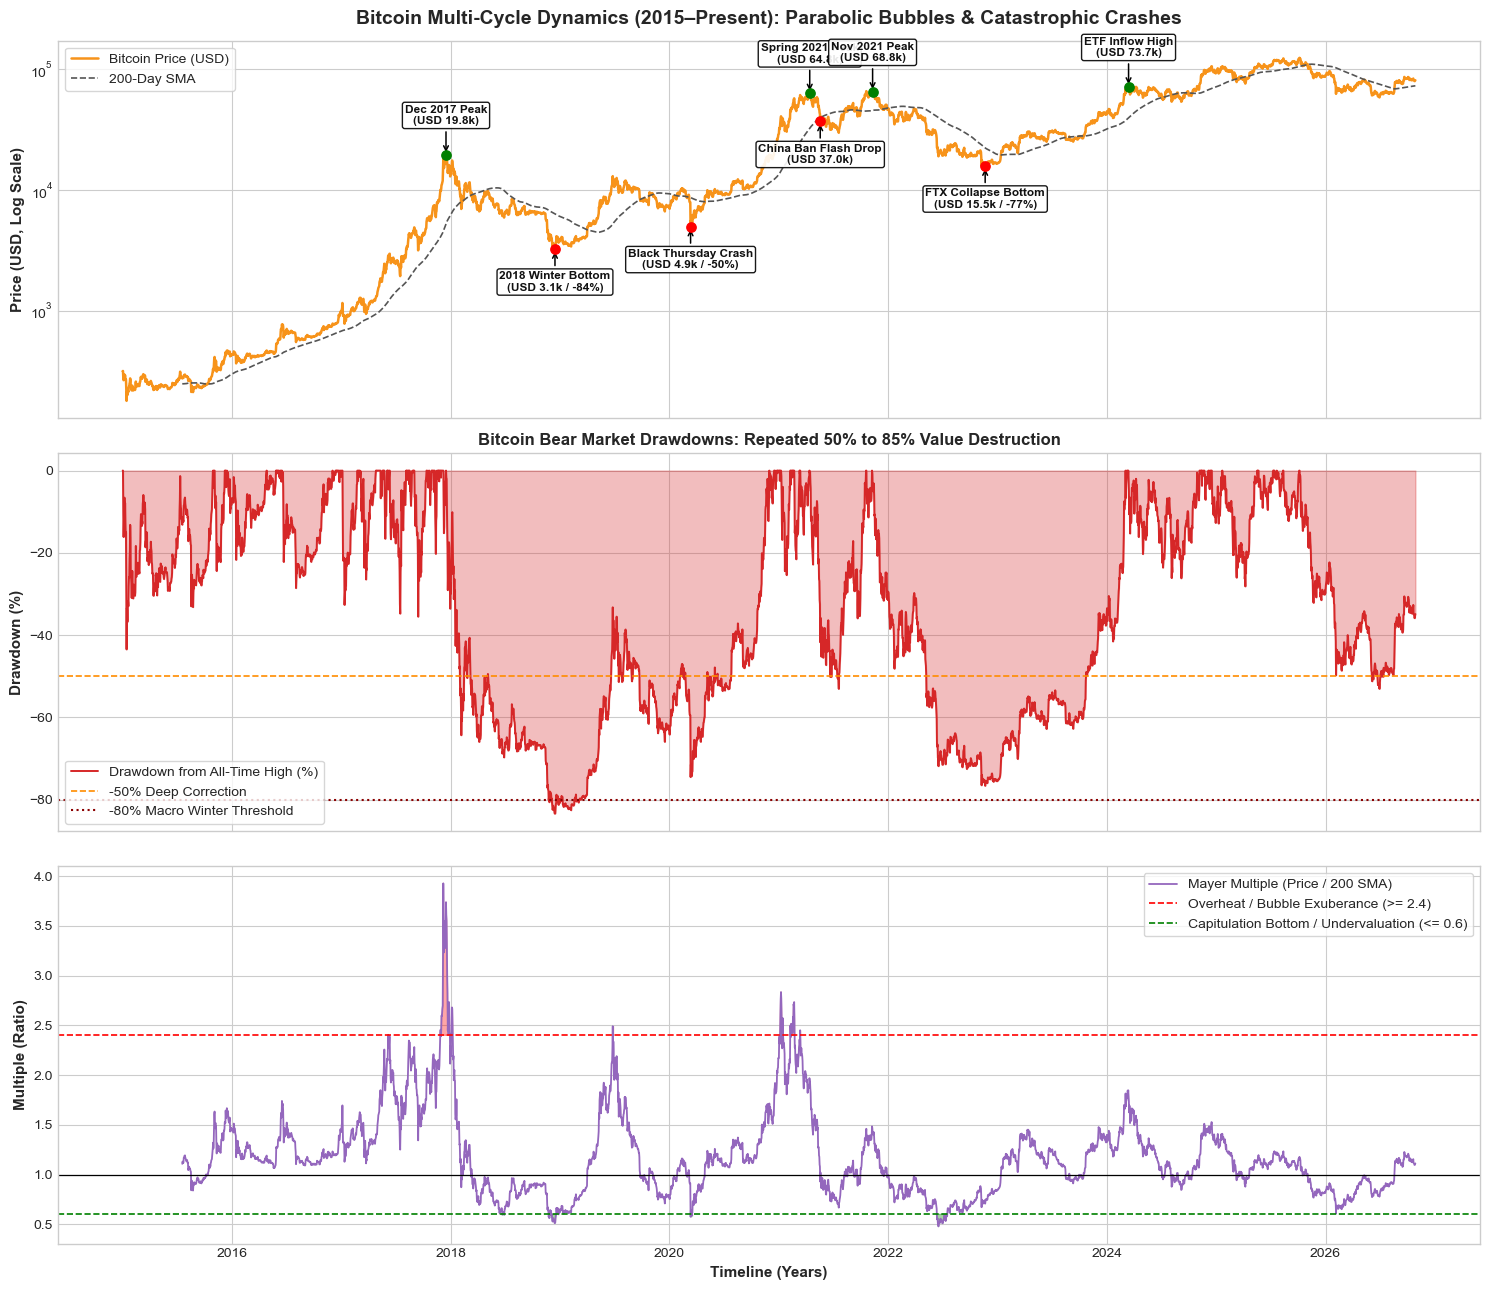

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. Log-Scale Price Trajectory with Cycle Highs and Liquidation Crashes
ax1 = axes[0]
ax1.plot(df_btc_proc['date'], df_btc_proc['BTC_close'], color='#f7931a', lw=1.8, label='Bitcoin Price (USD)')
ax1.plot(df_btc_proc['date'], df_btc_proc['sma_200'], color='#555555', lw=1.2, ls='--', label='200-Day SMA')
ax1.set_yscale('log')
ax1.set_title("Bitcoin Multi-Cycle Dynamics (2015–Present): Parabolic Bubbles & Catastrophic Crashes", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Price (USD, Log Scale)", fontsize=11, fontweight='bold')

btc_milestones = [
    ('2017-12-16', 'Dec 2017 Peak\n(USD 19.8k)', 19800, 'top'),
    ('2018-12-15', '2018 Winter Bottom\n(USD 3.1k / -84%)', 3150, 'bottom'),
    ('2020-03-12', 'Black Thursday Crash\n(USD 4.9k / -50%)', 4970, 'bottom'),
    ('2021-04-14', 'Spring 2021 Peak\n(USD 64.8k)', 64800, 'top'),
    ('2021-05-19', 'China Ban Flash Drop\n(USD 37.0k)', 37000, 'bottom'),
    ('2021-11-10', 'Nov 2021 Peak\n(USD 68.8k)', 68800, 'top'),
    ('2022-11-21', 'FTX Collapse Bottom\n(USD 15.5k / -77%)', 15500, 'bottom'),
    ('2024-03-14', 'ETF Inflow High\n(USD 73.7k)', 73700, 'top')
]

for date_str, label, y_val, va in btc_milestones:
    dt = pd.to_datetime(date_str)
    if dt in df_btc_proc['date'].values:
        actual = df_btc_proc.loc[df_btc_proc['date'] == dt, 'BTC_close'].values[0]
        ax1.scatter(dt, actual, color='red' if 'Bottom' in label or 'Crash' in label or 'Drop' in label else 'green', s=45, zorder=5)
        offset_mult = 0.45 if va=='bottom' else 1.8
        ax1.annotate(label, xy=(dt, actual), xytext=(dt, actual * offset_mult),
                     arrowprops=dict(arrowstyle="->", color='black', lw=1.1),
                     fontsize=8.5, fontweight='bold', color='#111111', ha='center',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax1.legend(loc='upper left', frameon=True)

# 2. Cumulative Drawdown Profile (% Underwater from Highs)
ax2 = axes[1]
ax2.plot(df_btc_proc['date'], df_btc_proc['drawdown_pct'], color='#d62728', lw=1.4, label='Drawdown from All-Time High (%)')
ax2.fill_between(df_btc_proc['date'], 0, df_btc_proc['drawdown_pct'], color='#d62728', alpha=0.3)
ax2.axhline(-50.0, color='darkorange', ls='--', lw=1.2, label='-50% Deep Correction')
ax2.axhline(-80.0, color='darkred', ls=':', lw=1.5, label='-80% Macro Winter Threshold')
ax2.set_ylabel("Drawdown (%)", fontsize=11, fontweight='bold')
ax2.set_title("Bitcoin Bear Market Drawdowns: Repeated 50% to 85% Value Destruction", fontsize=12, fontweight='bold')
ax2.legend(loc='lower left', frameon=True)

# 3. Mayer Multiple (Price / 200 SMA Overheat Indicator)
ax3 = axes[2]
ax3.plot(df_btc_proc['date'], df_btc_proc['mayer_multiple'], color='#9467bd', lw=1.3, label='Mayer Multiple (Price / 200 SMA)')
ax3.axhline(1.0, color='black', lw=0.9, ls='-')
ax3.axhline(2.4, color='red', ls='--', lw=1.2, label='Overheat / Bubble Exuberance (>= 2.4)')
ax3.axhline(0.6, color='green', ls='--', lw=1.2, label='Capitulation Bottom / Undervaluation (<= 0.6)')
ax3.fill_between(df_btc_proc['date'], 2.4, df_btc_proc['mayer_multiple'], 
                 where=(df_btc_proc['mayer_multiple'] >= 2.4), color='red', alpha=0.35)
ax3.fill_between(df_btc_proc['date'], df_btc_proc['mayer_multiple'], 0.6, 
                 where=(df_btc_proc['mayer_multiple'] <= 0.6), color='green', alpha=0.35)
ax3.set_ylabel("Multiple (Ratio)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Timeline (Years)", fontsize=11, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('data/btc_multicycle_timeline.png', dpi=300)
plt.show()

### 7. Flash Crash Ranking & Processed Export

In [5]:
# Top 10 worst single-day drops in Bitcoin history
top_btc_drops = df_btc_proc.sort_values('daily_return_pct').head(10)[['date', 'BTC_close', 'daily_return_pct', 'drawdown_pct', 'volatility_30d_ann']]
top_btc_drops['date'] = top_btc_drops['date'].dt.strftime('%Y-%m-%d')
print("=== Top 10 Steepest Single-Day Bitcoin Flash Drops (2015–Present) ===")
print(top_btc_drops.to_string(index=False))

# Export clean processed dataset
out_path = 'data/btc_multicycle_processed.csv'
df_btc_proc.to_csv(out_path, index=False)
print(f"\nProcessed Bitcoin dataset successfully saved to: {out_path}")

=== Top 10 Steepest Single-Day Bitcoin Flash Drops (2015–Present) ===
      date    BTC_close  daily_return_pct  drawdown_pct  volatility_30d_ann
2020-03-12  4970.788086        -37.169539    -74.505380          137.794451
2015-01-14   178.102997        -21.144862    -43.465112                 NaN
2017-09-14  3154.949951        -18.741101    -35.508102           93.754535
2015-08-18   211.078995        -18.178829    -32.997605           71.723740
2018-01-16 11490.500000        -16.854801    -41.066502          141.518577
2022-06-13 22487.388672        -15.974726    -66.718301           85.750966
2018-02-05  6955.270020        -15.968807    -64.327193          125.101927
2015-01-13   225.860992        -15.659308    -28.305384                 NaN
2016-01-15   364.330994        -15.332114    -21.703301           70.530537
2022-11-09 15880.780273        -14.349022    -76.496188           68.906091

Processed Bitcoin dataset successfully saved to: data/btc_multicycle_processed.csv
